In [2]:
import sys
import os
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

sys.path.append(os.path.abspath(".."))
from lakehouse import config
from lakehouse.spark_session import get_spark

spark = get_spark("EDA_Customer360")

# Load các bảng Delta
df_360 = spark.read.format("delta").load(config.GOLD_CUSTOMER360)
df_trend = spark.read.format("delta").load(config.GOLD_SEARCH_TREND)
df_silver_search = spark.read.format("delta").load(config.SILVER_SEARCH_CLEAN)

sns.set_theme(style="whitegrid")

## 1. Khẩu vị nội dung nào phổ biến nhất?

--- PHÂN BỐ KHẨU VỊ NỘI DUNG (MOST WATCH TYPE) ---


C:\Users\OS\AppData\Local\Temp\ipykernel_27664\449178746.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=taste_dist, x="count", y="most_watch_type", palette="viridis")


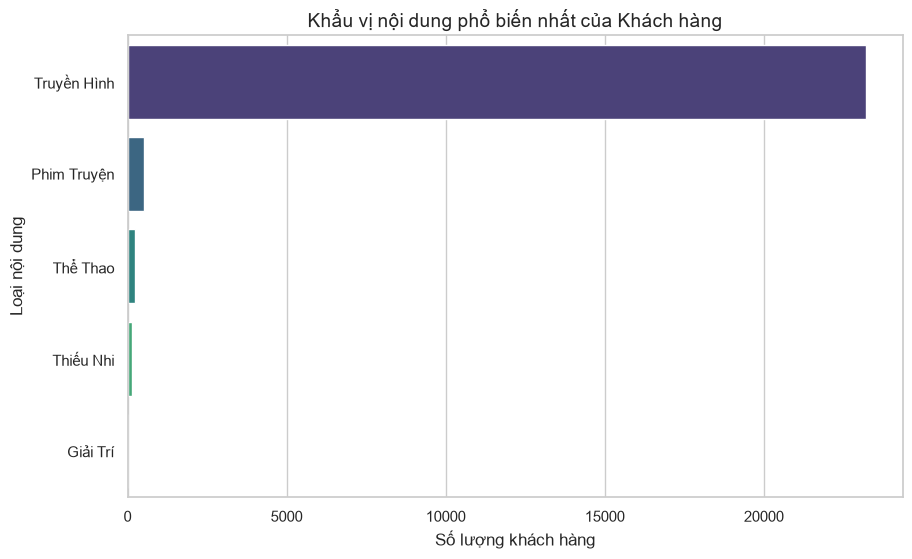

In [3]:
print("--- PHÂN BỐ KHẨU VỊ NỘI DUNG (MOST WATCH TYPE) ---")
# Aggregate bằng Spark, sau đó chuyển sang Pandas
taste_dist = (
    df_360.filter(F.col("most_watch_type").isNotNull())
    .groupBy("most_watch_type")
    .count()
    .orderBy(F.desc("count"))
    .toPandas()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=taste_dist, x="count", y="most_watch_type", palette="viridis")
plt.title("Khẩu vị nội dung phổ biến nhất của Khách hàng", fontsize=14)
plt.xlabel("Số lượng khách hàng")
plt.ylabel("Loại nội dung")
plt.show()

## 2. Nhóm khách nào dịch chuyển sở thích?

--- TOP 10 XU HƯỚNG DỊCH CHUYỂN SỞ THÍCH ---


C:\Users\OS\AppData\Local\Temp\ipykernel_27664\603515940.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=shift_df, x="count", y="category_transition", palette="magma")


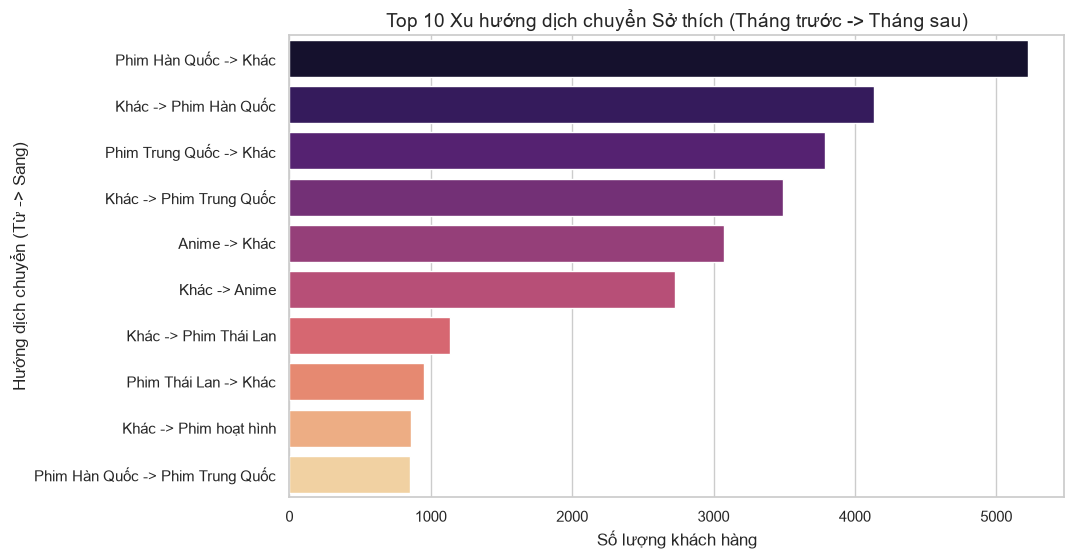

In [4]:
print("--- TOP 10 XU HƯỚNG DỊCH CHUYỂN SỞ THÍCH ---")
# Lọc những user có cờ dịch chuyển (category_shift_flag = True)
shift_df = (
    df_trend.filter(F.col("category_shift_flag") == True)
    .groupBy("category_transition")
    .count()
    .orderBy(F.desc("count"))
    .limit(10)
    .toPandas()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=shift_df, x="count", y="category_transition", palette="magma")
plt.title("Top 10 Xu hướng dịch chuyển Sở thích (Tháng trước -> Tháng sau)", fontsize=14)
plt.xlabel("Số lượng khách hàng")
plt.ylabel("Hướng dịch chuyển (Từ -> Sang)")
plt.show()

## 3. Keyword nào tăng/giảm mạnh nhất giữa T6 và T7?

--- TOP TỪ KHÓA TĂNG/GIẢM ĐỘT BIẾN GIỮA THÁNG 6 VÀ THÁNG 7 ---


C:\Users\OS\AppData\Local\Temp\ipykernel_27664\2780265649.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=trend_df, x="diff", y="keyword", palette=colors)


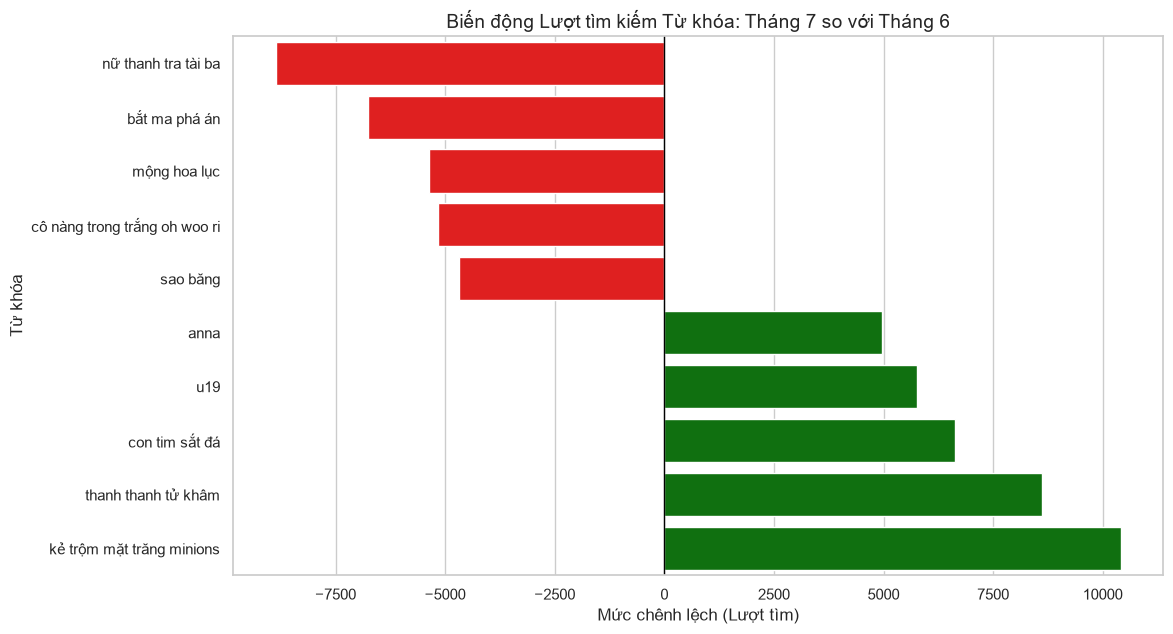

In [5]:
print("--- TOP TỪ KHÓA TĂNG/GIẢM ĐỘT BIẾN GIỮA THÁNG 6 VÀ THÁNG 7 ---")
# Trích xuất tháng từ bảng Silver Search để đếm chính xác tổng số lượt tìm
df_monthly_keyword = df_silver_search.withColumn("month", F.date_format("event_date", "yyyy-MM"))

# Pivot dữ liệu để so sánh T6 và T7
keyword_pivot = (
    df_monthly_keyword.groupBy("keyword")
    .pivot("month", ["2022-06", "2022-07"])
    .count()
    .fillna(0)
)

# Tính độ chênh lệch (Trend Drift)
keyword_trend = keyword_pivot.withColumn(
    "diff", F.col("2022-07") - F.col("2022-06")
).filter((F.col("2022-06") > 50) | (F.col("2022-07") > 50)) # Chỉ lấy keyword có volume tương đối

# Lấy top 5 tăng mạnh nhất và top 5 giảm mạnh nhất
top_increase = keyword_trend.orderBy(F.desc("diff")).limit(5).toPandas()
top_decrease = keyword_trend.orderBy(F.asc("diff")).limit(5).toPandas()

import pandas as pd
trend_df = pd.concat([top_increase, top_decrease]).sort_values("diff")

# Vẽ biểu đồ phân kỳ (Diverging bar chart)
plt.figure(figsize=(12, 7))
colors = ['red' if x < 0 else 'green' for x in trend_df['diff']]
sns.barplot(data=trend_df, x="diff", y="keyword", palette=colors)
plt.title("Biến động Lượt tìm kiếm Từ khóa: Tháng 7 so với Tháng 6", fontsize=14)
plt.xlabel("Mức chênh lệch (Lượt tìm)")
plt.ylabel("Từ khóa")
plt.axvline(0, color='black', linewidth=1)
plt.show()